# Experiments on the Quantinuum emulator `reimei-E`

This notebook runs the experiments of the paper that use the emulator through Quantinuum Nexus:

1. the noise strength inferred from echo circuits,
2. the two-copy measurement of a block of the Bures metric,
3. the survival of an echo circuit against its position in a packed program,
4. the federated training on a four-class task with IID data and with a Dirichlet label partition,
5. the federated training on the two-class task (shown once its campaign has finished).

**Run records.** Every cell that executes circuits ends by showing a *run record*: which program
produced the result (repository, commit, state of the working tree, entry point), when (start and end
of the cell, submission and completion of every job), and on which device (backend, device name,
error-rate multipliers, job identifiers, shots, cost).  The record is also saved as JSON next to the
results.  The commit is logged at the moment a job is submitted.

**Cache.** The shot tables of finished jobs are stored in the `results/` folders of this repository.
A cell whose results are all in the cache submits nothing and needs no login; its record then lists the
jobs that produced the cached results, with their original submission times and commits.

**No accidental jobs.** Every cell below passes `--cached-only`: it reads the cache and stops with an
error if a result is missing.  To repeat a measurement on the emulator, remove its cache folder, log in
with `qnx login`, remove `--cached-only` from the cell, and run it again.

In [1]:
import os, pathlib
REPO = pathlib.Path.cwd() if (pathlib.Path.cwd() / "qfedqgt").is_dir() else pathlib.Path.cwd().parent
os.chdir(REPO)                       # the scripts write to results/ relative to the repository root

from qfedqgt import provenance
info = provenance.program_info()
print("repository :", info["repository"])
print("commit     :", info["commit"])
print("modified   :", info["modified"] or "nothing (clean working tree)")

repository : https://github.com/HarukiEmori/qfl-qgt
commit     : 5b4a03a225ca414a405d1c2a4778aedebd286172
modified   : nothing (clean working tree)


## 0. Login check (only needed before a cell that submits jobs)

The check reports whether the stored Nexus login is valid.  It does not print the account.

In [2]:
from qfedqgt.nexus import login_status
print(login_status())

Nexus login: valid


## 1. Noise strength from echo circuits

The echo circuit `U` followed by `U^dagger` returns the all-zero outcome with a probability equal to the
purity of the state for global depolarizing noise.  The first cell uses the two-layer circuit of the
simulations, the second the one-layer circuit on four qubits of the four-class experiment, and the third and
fourth the one-layer circuits on two and three qubits (the circuit of the two-class experiment and a candidate
of its design study).  For the two-qubit circuit the frequency falls below 1/4, the value of the maximally
mixed state, at the multipliers 600 and 700; the two-class experiment uses the multiplier 400.

In [3]:
%run scripts/nexus_geometry.py --device reimei-E --scales 1 50 150 200 300 500 --shots 100 --cached-only

x1     survival 0.986+/-0.004 (local model 0.985)  p_hat 0.007 (local 0.008)


x50    survival 0.481+/-0.018 (local model 0.543)  p_hat 0.332 (local 0.284)


x150   survival 0.142+/-0.012 (local model 0.191)  p_hat 0.708 (local 0.629)


x200   survival 0.089+/-0.010 (local model 0.131)  p_hat 0.833 (local 0.730)


x300   survival 0.045+/-0.007 (local model 0.083)  p_hat 1.000 (local 0.853)


x500   survival 0.025+/-0.006 (local model 0.065)  p_hat 1.000 (local 0.951)


replay from the cache: results/nexus-geometry/reimei-E.json is reproduced


Program,task,noise strength from echo circuits
,entry point,scripts/nexus_geometry.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,5b4a03a225ca414a405d1c2a4778aedebd286172
,working tree,clean
When,started,2026-11-20T05:53:58-0800
,finished,2026-11-20T05:53:58-0800
,duration,0 s
,jobs submitted from,2026-11-19T00:16:24-0800
,last job completed,2026-11-19T00:22:42-0800
Device,kind,Quantinuum Nexus


In [4]:
%run scripts/nexus_geometry.py --device reimei-E --scenario emulator_iid --scales 1 100 200 300 400 500 --shots 100 --cached-only

x1     survival 0.985+/-0.004 (local model 0.991)  p_hat 0.008 (local 0.005)


x100   survival 0.471+/-0.018 (local model 0.533)  p_hat 0.340 (local 0.291)


x200   survival 0.236+/-0.015 (local model 0.290)  p_hat 0.569 (local 0.507)


x300   survival 0.124+/-0.012 (local model 0.169)  p_hat 0.744 (local 0.664)


x400   survival 0.072+/-0.009 (local model 0.110)  p_hat 0.897 (local 0.775)


x500   survival 0.045+/-0.007 (local model 0.082)  p_hat 1.000 (local 0.855)


replay from the cache: results/nexus-geometry/reimei-E-emulator_iid.json is reproduced


Program,task,noise strength from echo circuits
,entry point,scripts/nexus_geometry.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,5b4a03a225ca414a405d1c2a4778aedebd286172
,working tree,clean
When,started,2026-11-20T05:53:58-0800
,finished,2026-11-20T05:53:59-0800
,duration,0 s
,jobs submitted from,2026-11-19T01:42:23-0800
,last job completed,2026-11-19T01:46:38-0800
Device,kind,Quantinuum Nexus


In [5]:
%run scripts/nexus_geometry.py --device reimei-E --scenario calibration_n2 --scales 1 300 400 500 600 700 --shots 100 --cached-only

x1     survival 0.998+/-0.002 (local model 0.996)  p_hat 0.002 (local 0.002)


x300   survival 0.445+/-0.018 (local model 0.511)  p_hat 0.490 (local 0.411)


x400   survival 0.314+/-0.016 (local model 0.409)  p_hat 0.708 (local 0.539)


x500   survival 0.278+/-0.016 (local model 0.335)  p_hat 0.809 (local 0.664)


x600   survival 0.196+/-0.014 (local model 0.285)  p_hat 1.000 (local 0.783)


x700   survival 0.172+/-0.013 (local model 0.258)  p_hat 1.000 (local 0.895)


replay from the cache: results/nexus-geometry/reimei-E-calibration_n2.json is reproduced


Program,task,noise strength from echo circuits
,entry point,scripts/nexus_geometry.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,5b4a03a225ca414a405d1c2a4778aedebd286172
,working tree,clean
When,started,2026-11-20T05:53:59-0800
,finished,2026-11-20T05:53:59-0800
,duration,0 s
,jobs submitted from,2026-11-20T04:27:55-0800
,last job completed,2026-11-20T04:43:48-0800
Device,kind,Quantinuum Nexus


In [6]:
%run scripts/nexus_geometry.py --device reimei-E --scenario calibration_n3 --scales 1 300 400 500 600 700 --shots 100 --cached-only

x1     survival 0.995+/-0.002 (local model 0.994)  p_hat 0.003 (local 0.004)


x300   survival 0.239+/-0.015 (local model 0.292)  p_hat 0.639 (local 0.563)


x400   survival 0.180+/-0.014 (local model 0.209)  p_hat 0.749 (local 0.690)


x500   survival 0.113+/-0.011 (local model 0.163)  p_hat 1.000 (local 0.792)


x600   survival 0.076+/-0.009 (local model 0.139)  p_hat 1.000 (local 0.873)


x700   survival 0.059+/-0.008 (local model 0.129)  p_hat 1.000 (local 0.936)


replay from the cache: results/nexus-geometry/reimei-E-calibration_n3.json is reproduced


Program,task,noise strength from echo circuits
,entry point,scripts/nexus_geometry.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,5b4a03a225ca414a405d1c2a4778aedebd286172
,working tree,clean
When,started,2026-11-20T05:53:59-0800
,finished,2026-11-20T05:53:59-0800
,duration,0 s
,jobs submitted from,2026-11-20T04:27:46-0800
,last job completed,2026-11-20T04:41:17-0800
Device,kind,Quantinuum Nexus


## 2. Two-copy measurement of the Bures metric

A destructive SWAP test on two copies of the state gives the overlaps `Tr[rho_a rho_b]`; with the
parameter-shift rule they give `Tr[(d_i rho)(d_j rho)]`, and the purity gives the factor that turns it
into the Bures metric.  The cell measures the 8 x 8 block of the second layer at one input.

In [7]:
%run scripts/nexus_metric.py --backend nexus --device reimei-E --scales 1 50 --shots 200 --layer 1 --cached-only

x1     purity 0.980 (local model 0.980, state 0.987)  Tr G 1.119+/-0.042 (local estimator 1.170, exact 1.187, noiseless 1.196)  rms dev 0.020 / se 0.015


x50    purity 0.440 (local model 0.462, state 0.527)  Tr G 0.667+/-0.085 (local estimator 0.649, exact 0.818, noiseless 1.196)  rms dev 0.032 / se 0.026


replay from the cache: results/metric/reimei-E.json is reproduced


Program,task,two-copy measurement of the Bures metric
,entry point,scripts/nexus_metric.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,5b4a03a225ca414a405d1c2a4778aedebd286172
,working tree,clean
When,started,2026-11-20T05:53:59-0800
,finished,2026-11-20T05:54:22-0800
,duration,23 s
,jobs submitted from,2026-11-19T01:10:49-0800
,last job completed,2026-11-19T01:37:31-0800
Device,kind,Quantinuum Nexus


## 3. Position of a circuit in a packed program

The circuits of a round are packed into programs in which the qubits are measured, reset and reused.
One program with 600 copies of the same echo circuit shows whether a circuit late in the program is as
reliable as an early one: the frequency of the all-zero outcome is recorded for every position.

In [8]:
%run scripts/nexus_position.py --device reimei-E --scales 1 300 --shots 60 20 --circuits 600 --cached-only

cost formula (HQC): x1: 898, x300: 303


x1     survival 0.9903+/-0.0005 (local model 0.9909)  change from the first to the last circuit -0.0024+/-0.0018 (-1.3 standard errors)  quarters 0.9912 0.9914 0.9886 0.9899 (+/-0.0010)


x300   survival 0.1191+/-0.0030 (local model 0.1703)  change from the first to the last circuit +0.0030+/-0.0102 (+0.3 standard errors)  quarters 0.1133 0.1300 0.1097 0.1233 (+/-0.0059)


replay from the cache: results/nexus-position/reimei-E.json is reproduced


Program,task,survival of an echo circuit against its position in a packed program
,entry point,scripts/nexus_position.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,5b4a03a225ca414a405d1c2a4778aedebd286172
,working tree,clean
When,started,2026-11-20T05:54:22-0800
,finished,2026-11-20T05:54:22-0800
,duration,0 s
,jobs submitted from,2026-11-20T03:32:00-0800
,last job completed,2026-11-20T03:58:29-0800
Device,kind,Quantinuum Nexus


## 4. Federated training on the emulator: four-class task

Sixteen seeds with IID data and the same seeds with a Dirichlet label partition were run.  The runs of a
campaign advance round by round together, and the circuits of a round are submitted at once.  Four
clients take part: two reference clients with 30 shots per circuit and two clients with 300-fold error
rates and one shot per circuit.  The step sizes were selected with the local gate-level model on
separate tuning seeds (`scripts/run_campaign.py tune --scenarios emulator_iid emulator_dirichlet`).
After the last round the models of the last five rounds are evaluated on the emulator with the
reference error rates.

The experiment was executed as 2 campaigns with the same protocol: `emulator-reimei-E` (seeds 0 to 5) and `emulator-reimei-E-2` (seeds 6 to 15).
The seeds and the packing of the circuits into programs are stored in `packing.json` of every result
folder and are reused by the cells below.

In [9]:
%run scripts/run_emulator.py --backend nexus --device reimei-E --name emulator-reimei-E --cached-only

round   1  noiseless accuracy, mean over the runs: QFedAvg=0.211  QFedFisher=0.215  QFedQGT=0.197  (0 s)


round   2  noiseless accuracy, mean over the runs: QFedAvg=0.235  QFedFisher=0.196  QFedQGT=0.205  (0 s)


round   3  noiseless accuracy, mean over the runs: QFedAvg=0.255  QFedFisher=0.217  QFedQGT=0.236  (0 s)


round   4  noiseless accuracy, mean over the runs: QFedAvg=0.244  QFedFisher=0.229  QFedQGT=0.262  (0 s)


round   5  noiseless accuracy, mean over the runs: QFedAvg=0.231  QFedFisher=0.219  QFedQGT=0.266  (0 s)


round   6  noiseless accuracy, mean over the runs: QFedAvg=0.280  QFedFisher=0.242  QFedQGT=0.300  (1 s)


... (20 outputs left out)

emulator_dirichlet     seed 5  QFedAvg: device 0.397 noiseless 0.363  QFedFisher: device 0.287 noiseless 0.250  QFedQGT: device 0.407 noiseless 0.390


replay from the cache: results/emulator-reimei-E/summary.json is reproduced


replay from the cache: 13 of 13 stored result files are reproduced


Program,task,federated training of several runs in lockstep
,entry point,scripts/run_emulator.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,5b4a03a225ca414a405d1c2a4778aedebd286172
,working tree,clean
When,started,2026-11-20T05:54:23-0800
,finished,2026-11-20T05:54:25-0800
,duration,1 s
,jobs submitted from,2026-11-19T03:26:58-0800
,last job completed,2026-11-19T10:10:42-0800
Device,kind,Quantinuum Nexus


In [10]:
%run scripts/run_emulator.py --backend nexus --device reimei-E --name emulator-reimei-E-2 --cached-only

round   1  noiseless accuracy, mean over the runs: QFedAvg=0.203  QFedFisher=0.175  QFedQGT=0.167  (0 s)


round   2  noiseless accuracy, mean over the runs: QFedAvg=0.228  QFedFisher=0.185  QFedQGT=0.204  (0 s)


round   3  noiseless accuracy, mean over the runs: QFedAvg=0.250  QFedFisher=0.202  QFedQGT=0.199  (0 s)


round   4  noiseless accuracy, mean over the runs: QFedAvg=0.234  QFedFisher=0.214  QFedQGT=0.228  (1 s)


round   5  noiseless accuracy, mean over the runs: QFedAvg=0.280  QFedFisher=0.233  QFedQGT=0.242  (1 s)


round   6  noiseless accuracy, mean over the runs: QFedAvg=0.279  QFedFisher=0.247  QFedQGT=0.287  (1 s)


... (28 outputs left out)

emulator_dirichlet     seed 15  QFedAvg: device 0.227 noiseless 0.228  QFedFisher: device 0.367 noiseless 0.455  QFedQGT: device 0.480 noiseless 0.488


replay from the cache: results/emulator-reimei-E-2/summary.json is reproduced


replay from the cache: 21 of 21 stored result files are reproduced


Program,task,federated training of several runs in lockstep
,entry point,scripts/run_emulator.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,5b4a03a225ca414a405d1c2a4778aedebd286172
,working tree,clean
When,started,2026-11-20T05:54:27-0800
,finished,2026-11-20T05:54:29-0800
,duration,2 s
,jobs submitted from,2026-11-19T10:23:26-0800
,last job completed,2026-11-20T05:36:54-0800
Device,kind,Quantinuum Nexus


## 5. Summary of the training

`device` is the test accuracy measured on the emulator (mean over the last five rounds), and `noiseless`
is the accuracy of the noiseless circuit with the same parameters.  The differences are QFedQGT minus the
baseline in percentage points with the standard error of the paired difference.

In [11]:
%run scripts/emulator_summary.py

=== experiment four_class: emulator-reimei-E, emulator-reimei-E-2
IID data: 16 seeds
  QFedAvg     device 0.310 +/- 0.023   noiseless 0.307 +/- 0.024
  QFedFisher  device 0.274 +/- 0.017   noiseless 0.287 +/- 0.018
  QFedQGT     device 0.393 +/- 0.022   noiseless 0.398 +/- 0.026
  QFedQGT - QFedAvg     (device   )  +8.3 +/-  2.8 points, higher in 11 of 16 seeds   by campaign: +7.0 +/- 5.3 (6 seeds), +9.1 +/- 3.4 (10 seeds)
  QFedQGT - QFedAvg     (noiseless)  +9.1 +/-  2.6 points, higher in 13 of 16 seeds   by campaign: +9.4 +/- 3.1 (6 seeds), +8.9 +/- 3.9 (10 seeds)
  QFedQGT - QFedFisher  (device   ) +11.9 +/-  2.9 points, higher in 14 of 16 seeds   by campaign: +11.7 +/- 5.3 (6 seeds), +12.0 +/- 3.5 (10 seeds)
  QFedQGT - QFedFisher  (noiseless) +11.0 +/-  3.0 points, higher in 13 of 16 seeds   by campaign: +10.3 +/- 6.5 (6 seeds), +11.5 +/- 3.1 (10 seeds)
Dirichlet partition: 16 seeds
  QFedAvg     device 0.300 +/- 0.015   noiseless 0.281 +/- 0.018
  QFedFisher  device 0.314 +/- 0.

In [12]:
%run scripts/make_figures.py emulator

wrote figures/emulator.pdf and figures/emulator.png


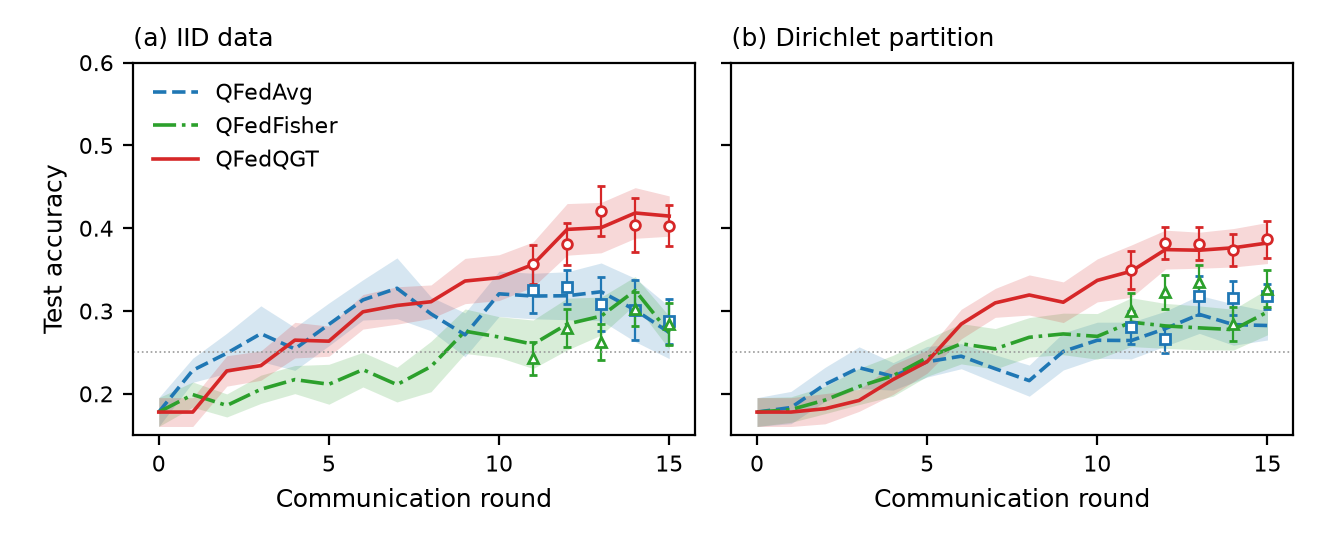

In [13]:
from IPython.display import Image
Image(filename=str(REPO / "figures" / "emulator.png"), width=700)

In [14]:
# the saved run records can be shown again at any time
provenance.load_record(str(REPO / "results" / "metric" / "reimei-E-provenance.json"))

Program,task,two-copy measurement of the Bures metric
,entry point,scripts/nexus_metric.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,590741b058c461fce72cc355c4228509af82f0a1
,working tree,"modified: notebooks/, scripts/nexus_metric.py"
When,started,2026-11-19T04:06:40-0800
,finished,2026-11-19T04:07:03-0800
,duration,23 s
,jobs submitted from,2026-11-19T01:10:49-0800
,last job completed,2026-11-19T01:37:31-0800
Device,kind,Quantinuum Nexus
